# TP Deep Learning : Classification de Lésions Cutanées (HAM500)

**Master Machine Learning et Intelligence Multimédia**  
**Étudiant :** EL MAKHLOUFI Mohammed  
**Enseignant :** Pr. Abdelouahed Sabri

---

## Objectif du TP
Ce travail pratique consiste à réaliser une étude comparative de 4 architectures de Deep Learning (CNN, VGG16, ResNet50, ViT) pour la classification multicasse d'images de lésions cutanées (7 classes). Nous allons tester 2 stratégies d'entraînement : **From Scratch** (à partir de zéro) et **Fine-Tuning** (avec des poids pré-entraînés sur ImageNet).


## Partie 1 : Exploration et Prétraitement des Données
Dans cette première partie, nous allons :
1. Charger les métadonnées et les images depuis Google Drive.
2. Explorer la distribution des classes.
3. Prétraiter les images (redimensionnement en 224x224) et diviser le dataset en 3 ensembles (64% Train, 16% Val, 20% Test).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DATASET_DIR = '/content/drive/MyDrive/HAM5000'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 1.1 Importation des bibliothèques et configuration
Nous importons les bibliothèques nécessaires pour la manipulation des données, l'affichage et le Deep Learning (TensorFlow/Keras).

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical
import random

### 1.2 Exploration des données
Nous chargeons le fichier CSV contenant les métadonnées (identifiants, noms des images et labels). Ensuite, nous affichons les premières lignes, le nombre total d'images, et la distribution des classes.

In [ ]:
csv_path = os.path.join(DATASET_DIR, 'HAM500_metadata.csv')
df = pd.read_csv(csv_path, sep=';')

# 1. Afficher les premières lignes
print("--- Premières lignes du dataset ---")
display(df.head())

--- Premières lignes du dataset ---


,lesion_id,image_id,label
0,HAM_0000550,ISIC_0024306,nv
1,HAM_0003577,ISIC_0024307,nv
2,HAM_0001477,ISIC_0024308,nv
3,HAM_0000484,ISIC_0024309,nv
4,HAM_0003350,ISIC_0024310,mel


In [ ]:
# 2. Nombre total d'images et de classes
print(f"\nNombre total d'images : {len(df)}")
print(f"Nombre de classes : {df['label'].nunique()}")


Nombre total d'images : 500
Nombre de classes : 7


In [ ]:
# 3. Distribution des classes
print("\nDistribution des classes :")
print(df['label'].value_counts())


Distribution des classes :
label
nv       332
bkl       57
mel       43
bcc       34
akiec     21
vasc       8
df         5
Name: count, dtype: int64


/tmp/ipykernel_2771/1111079022.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='viridis')


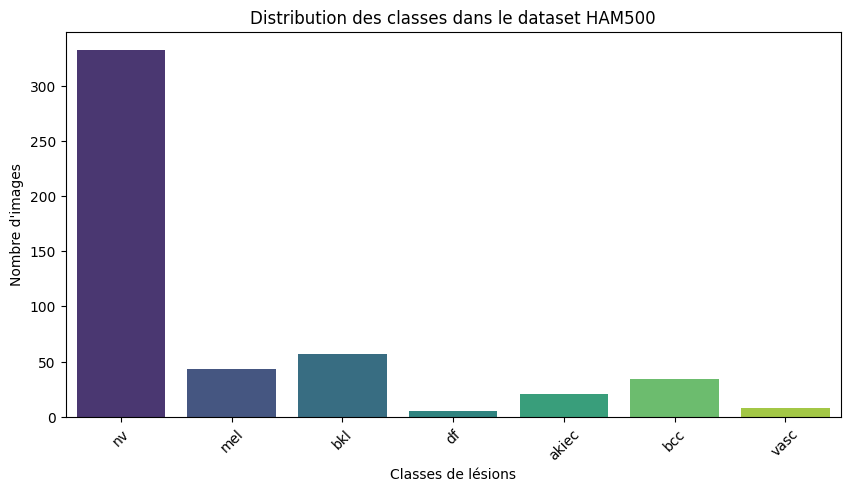

In [ ]:
# 4. Représentation graphique de la distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='label', palette='viridis')
plt.title('Distribution des classes dans le dataset HAM500')
plt.xlabel('Classes de lésions')
plt.ylabel("Nombre d'images")
plt.xticks(rotation=45)
plt.show()

### Visualisation d'exemples d'images

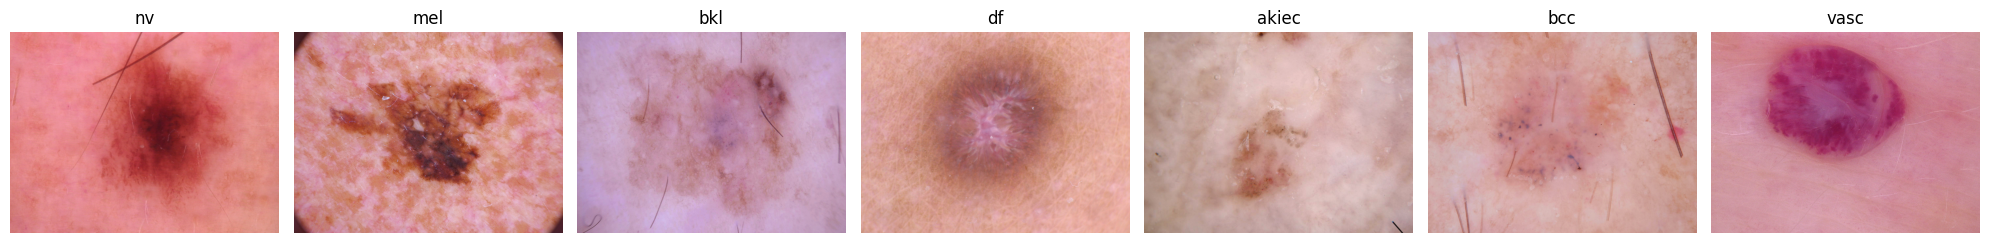

In [ ]:
# Afficher une image par classe
fig, axes = plt.subplots(1, 7, figsize=(20, 4))
classes = df['label'].unique()

for i, cls in enumerate(classes):
    # Prendre la première image de cette classe
    img_id = df[df['label'] == cls]['image_id'].values[0]

    img_path = os.path.join(DATASET_DIR, 'HAM500_images', str(img_id) + '.jpg')
    if not os.path.exists(img_path):
        img_path = os.path.join(DATASET_DIR, 'HAM500_images', str(img_id) + '.png')

    img = cv2.imread(img_path)
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[i].imshow(img)
        axes[i].set_title(cls)
    else:
        axes[i].text(0.5, 0.5, 'Image introuvable\n' + str(img_id), ha='center')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### 1.3 Prétraitement et Division des données
Conformément à l'énoncé :
- Les images sont redimensionnées en **224 × 224 pixels**.
- Les étiquettes sont encodées (Label Encoding puis One-Hot Encoding pour la Categorical Crossentropy).
- Le dataset est divisé en **64% Train, 16% Validation, 20% Test** (avec `stratify` pour garder les proportions).

In [ ]:
IMG_SIZE = (224, 224)
images = []
labels = []

print("Chargement des images en cours...")
for index, row in df.iterrows():
    img_path = os.path.join(DATASET_DIR, 'HAM500_images', row['image_id'] + '.jpg')
    img = cv2.imread(img_path)

    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, IMG_SIZE)
        images.append(img)
        labels.append(row['label'])

X = np.array(images, dtype='float32')
y = np.array(labels)

print(f"Chargement terminé ! {len(X)} images chargées avec succès.")

# 2. Encodage des étiquettes (Label Encoding)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nMapping des classes :")
for i, cls in enumerate(le.classes_):
    print(f"{i} : {cls}")

# 3. Division : 64% Train, 16% Val, 20% Test
# D'abord, on sépare le Test (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

# Ensuite, on sépare le reste en Train (64%) et Validation (16%)
# 16% corresponds to 0.20 of the remaining 80% (16/80 = 0.2)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.20, random_state=42, stratify=y_temp
)

print(f"\nTaille de l'ensemble d'entraînement : {X_train.shape[0]} images")
print(f"Taille de l'ensemble de validation  : {X_val.shape[0]} images")
print(f"Taille de l'ensemble de test        : {X_test.shape[0]} images")

# 4. One-Hot Encoding pour la Categorical Crossentropy
NUM_CLASSES = len(le.classes_)
y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_val_cat = to_categorical(y_val, NUM_CLASSES)
y_test_cat = to_categorical(y_test, NUM_CLASSES)

print(f"\nForme de y_train_cat : {y_train_cat.shape}")

Chargement des images en cours...
Chargement terminé ! 500 images chargées avec succès.

Mapping des classes :
0 : akiec
1 : bcc
2 : bkl
3 : df
4 : mel
5 : nv
6 : vasc

Taille de l'ensemble d'entraînement : 320 images
Taille de l'ensemble de validation  : 80 images
Taille de l'ensemble de test        : 100 images

Forme de y_train_cat : (320, 7)


## Partie 2 : Construction et entraînement d'un CNN personnalisé

Dans cette partie, nous construisons un réseau de neurones convolutionnel (CNN) "From Scratch".

L'architecture est composée de blocs de convolutions successifs (32, 64, 128, 256 filtres) suivis de MaxPooling, puis d'un GlobalAveragePooling pour aplatir les caractéristiques, et enfin d'une tête de

* classification (Dense 128 -> Dropout -> Dense 7 avec Softmax).

In [ ]:
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout
from keras.optimizers import Adam

def build_custom_cnn(input_shape=(224, 224, 3), num_classes=7):
    model = Sequential([

        Input(shape=input_shape),

        # Bloc 1
        Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),

        # Bloc 2
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),

        # Bloc 3
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),

        # Bloc 4
        Conv2D(256, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),

        # Aplatissement
        GlobalAveragePooling2D(),

        # Tête de classification
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model

cnn_model = build_custom_cnn(input_shape=(224, 224, 3), num_classes=NUM_CLASSES)

* résumé de l'architecture.
* le nombre total de paramètres.

In [ ]:
print("--- Résumé de l'architecture du CNN ---")
cnn_model.summary()

total_params = cnn_model.count_params()
print(f"\nNombre total de paramètres : {total_params:,}")

--- Résumé de l'architecture du CNN ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_55 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 615,975 (2.35 MB)

 Trainable params: 615,975 (2.35 MB)

 Non-trainable params: 0 (0.00 B)


Nombre total de paramètres : 615,975


### 4. Entraîner le modèle

Nous compilons le modèle avec l'optimiseur Adam (learning rate = 0.001) et la fonction de perte Categorical Crossentropy.
L'entraînement utilise un batch size de 16 et un maximum de 30 époques. Un `EarlyStopping` est configuré avec une patience de 5 époques pour arrêter l'entraînement si la perte de validation ne s'améliore plus, tout en restaurant les meilleurs poids.

In [ ]:
import time
from keras.callbacks import EarlyStopping

cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 2. Configuration de l'Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("Début de l'entraînement...")
start_time = time.time()

history_cnn = cnn_model.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    batch_size=16,
    epochs=30,
    callbacks=[early_stop],
    verbose=1
)

end_time = time.time()
training_time_cnn = end_time - start_time
print(f"\nTemps d'entraînement : {training_time_cnn:.2f} secondes")

Début de l'entraînement...
Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 181ms/step - accuracy: 0.5906 - loss: 1.9882 - val_accuracy: 0.6625 - val_loss: 1.1031
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - accuracy: 0.6656 - loss: 1.2522 - val_accuracy: 0.6625 - val_loss: 1.2088
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - accuracy: 0.6656 - loss: 1.0995 - val_accuracy: 0.6625 - val_loss: 1.0323
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step - accuracy: 0.6656 - loss: 1.1628 - val_accuracy: 0.6625 - val_loss: 1.0456
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - accuracy: 0.6406 - loss: 1.3119 - val_accuracy: 0.6625 - val_loss: 1.2694
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 0.6656 - loss: 1.0540 - val_accuracy: 0.6625 - val_loss: 0.9924
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 0.6656 - loss: 1.0775 - val_accuracy: 0.6625 - val_loss: 0.9954
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.6656 - loss: 1

### 5. Afficher les courbes d'accuracy et de loss

Nous visualisons l'évolution de l'accuracy et de la perte (loss) pour les ensembles d'entraînement et de validation. Cela permet d'observer si le modèle converge correctement ou s'il présente des signes de sur-apprentissage (overfitting).

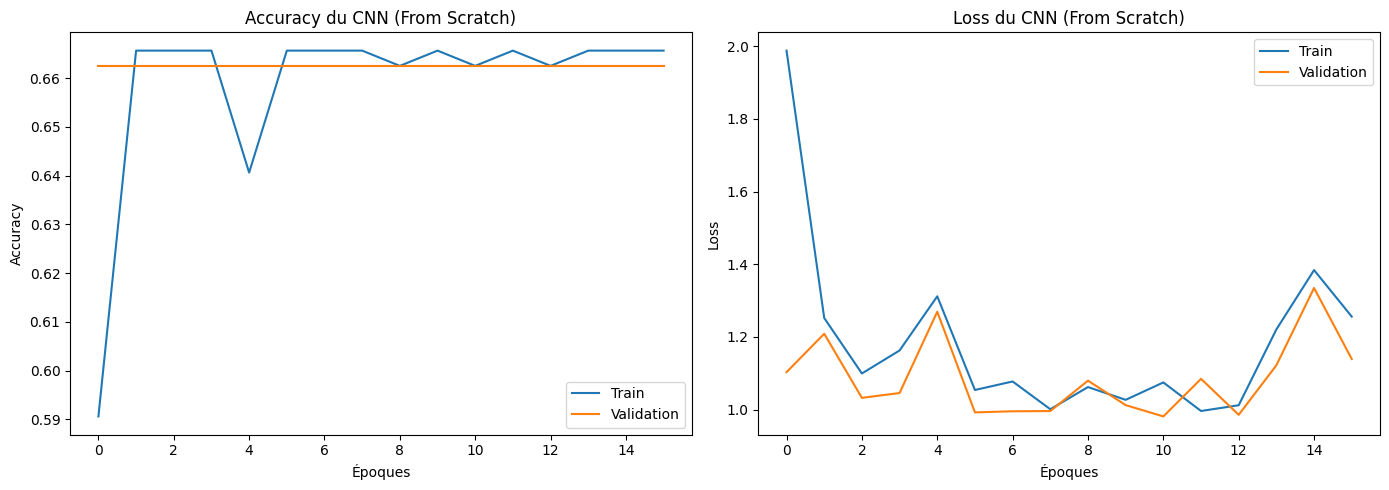

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Courbe Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['accuracy'], label='Train')
plt.plot(history_cnn.history['val_accuracy'], label='Validation')
plt.title('Accuracy du CNN (From Scratch)')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()

# Courbe Loss
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['loss'], label='Train')
plt.plot(history_cnn.history['val_loss'], label='Validation')
plt.title('Loss du CNN (From Scratch)')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### Afficher la matrice de confusion

* La matrice de confusion nous permet de voir exactement quelles classes le modèle confond. Chaque ligne représente la vraie classe, et chaque colonne la classe prédite par le réseau.

### Calculer les métriques (Accuracy, Precision, Recall, F1-score)

Test Loss : 1.0193
Test Accuracy : 0.6600
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 193ms/step


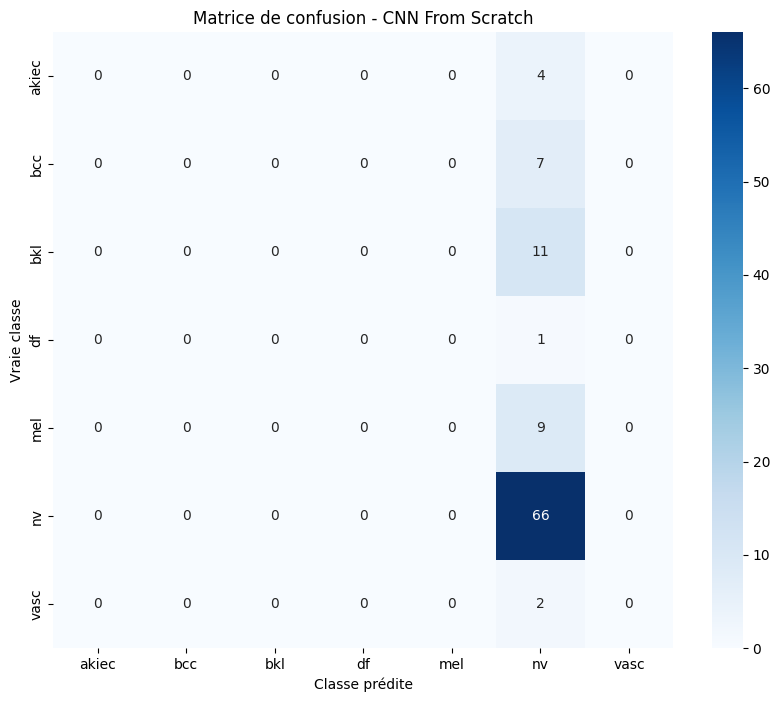


--- Rapport de classification ---
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00         4
         bcc       0.00      0.00      0.00         7
         bkl       0.00      0.00      0.00        11
          df       0.00      0.00      0.00         1
         mel       0.00      0.00      0.00         9
          nv       0.66      1.00      0.80        66
        vasc       0.00      0.00      0.00         2

    accuracy                           0.66       100
   macro avg       0.09      0.14      0.11       100
weighted avg       0.44      0.66      0.52       100



In [ ]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np

# 1. Évaluation sur le Test
test_loss, test_acc = cnn_model.evaluate(X_test, y_test_cat, verbose=0)
print(f"Test Loss : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f}")

# 2. Prédictions
y_pred_probs = cnn_model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Matrice de confusion - CNN From Scratch')
plt.ylabel('Vraie classe')
plt.xlabel('Classe prédite')
plt.show()

# 4. Rapport de classification (Accuracy, Precision, Recall, F1)
print("\n--- Rapport de classification ---")
print(classification_report(y_test, y_pred, target_names=le.classes_))

### Enregistrer le temps d'entraînement et sauvegarder le meilleur modèle

In [ ]:
# Sauvegarde du modèle au format .keras
model_filename = '/content/drive/MyDrive/HAM5000/cnn_custom_scratch.keras'
cnn_model.save(model_filename)

print(f"Modèle sauvegardé avec succès sous : {model_filename}")
print(f"Temps d'entraînement total : {training_time_cnn / 60 :.2f} min")

Modèle sauvegardé avec succès sous : /content/drive/MyDrive/HAM5000/cnn_custom_scratch.keras
Temps d'entraînement total : 70.88 min


## Partie 3 : Étude de l'architecture VGG16

Contrairement au CNN précédent, VGG16 est un modèle beaucoup plus profond (16 couches). Nous allons tester deux approches :
1. **From Scratch** : On initialise les poids au hasard et on entraîne tout le réseau. (Attention : avec seulement 500 images, ça risque d'être difficile).
2. **Fine-Tuning** : On charge les poids pré-entraînés sur ImageNet (qui connaissent déjà les formes et textures) et on les adapte à nos 7 classes de lésions.

In [ ]:
from keras.applications import VGG16
from keras.models import Model
from keras.layers import GlobalAveragePooling2D, Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
import time

# 1. Charger VGG16 sans les couches de classification originales et sans poids préentraînés
base_model_vgg = VGG16(weights=None, include_top=False, input_shape=(224, 224, 3))

# 2. Ajouter la tête de classification
x = base_model_vgg.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

vgg_scratch = Model(inputs=base_model_vgg.input, outputs=predictions)

# 3. Entraîner toutes les couches
vgg_scratch.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

print("Début de l'entraînement VGG16 - From Scratch...")
start_time = time.time()

history_vgg_scratch = vgg_scratch.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    batch_size=16,
    epochs=30,
    callbacks=[early_stop],
    verbose=1
)

time_vgg_scratch = time.time() - start_time
minutes = int(time_vgg_scratch // 60)
print(f"Temps d'entraînement : {minutes} min")

# Sauvegarde du modèle
vgg_scratch.save('/content/drive/MyDrive/HAM5000/vgg16_scratch.keras')

Début de l'entraînement VGG16 - From Scratch...
Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 385ms/step - accuracy: 0.5875 - loss: 1.4150 - val_accuracy: 0.6625 - val_loss: 1.1150
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 245ms/step - accuracy: 0.6625 - loss: 1.1811 - val_accuracy: 0.6625 - val_loss: 1.2400
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 247ms/step - accuracy: 0.6656 - loss: 1.3121 - val_accuracy: 0.6625 - val_loss: 1.1107
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 248ms/step - accuracy: 0.6656 - loss: 1.2263 - val_accuracy: 0.6625 - val_loss: 1.2557
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 250ms/step - accuracy: 0.6656 - loss: 1.1705 - val_accuracy: 0.6625 - val_loss: 1.0455
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 251ms/step - accuracy: 0.6656 - loss: 1.0947 - val_accuracy: 0.6625 - val_loss: 1.0572
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 256ms/step - accuracy: 0.6656 - loss: 1.1132 - val_accuracy: 0.6625 - val_loss: 1.0023
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 259ms/step - a

### Expérience 2 : VGG16 Fine-Tuning

Ici, on utilise la puissance de VGG16. On charge les poids d'ImageNet (`weights='imagenet'`), on remplace la dernière couche par nos 7 classes, et on ré-entraîne le tout avec un learning rate très petit (0.00001) pour ne pas "casser" ce que le modèle a déjà appris.

In [ ]:
# 1. Charger VGG16 avec poids ImageNet
base_model_vgg_ft = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# 2. Remplacer la tête de classification
x = base_model_vgg_ft.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

vgg_finetune = Model(inputs=base_model_vgg_ft.input, outputs=predictions)

# 3 & 4. Toutes les couches sont entraînables par défaut dans Keras, on compile avec LR=0.00001
vgg_finetune.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

print("Début de l'entraînement VGG16 - Fine-Tuning...")
start_time = time.time()

history_vgg_ft = vgg_finetune.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    batch_size=16,
    epochs=30,
    callbacks=[early_stop],
    verbose=1
)

time_vgg_ft = time.time() - start_time
minutes = int(time_vgg_ft // 60)
print(f"Temps d'entraînement : {minutes} min")

vgg_finetune.save('/content/drive/MyDrive/HAM5000/vgg16_finetune.keras')

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Début de l'entraînement VGG16 - Fine-Tuning...
Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 318ms/step - accuracy: 0.4437 - loss: 2.3362 - val_accuracy: 0.6625 - val_loss: 1.1150
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 264ms/step - accuracy: 0.6062 - loss: 1.2254 - val_accuracy: 0.6625 - val_loss: 1.0342
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 267ms/step - accuracy: 0.6406 - loss: 1.0494 - val_accuracy: 0.6125 - val_loss: 1.0135
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 271ms/step - accuracy: 0.6719 - loss: 0.9299 - val_accuracy: 0.6000 - val_loss: 0.9560
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 273ms/step - accuracy: 0.6687 - loss: 0.9095 - val_accuracy: 0.6125 - val_loss: 0.9574
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 276ms/step - accuracy: 0.7281 - loss: 0.7514 - val_accuracy: 0.6500 - val_loss: 0.9774
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 276ms/step - accuracy: 0.7312 - loss: 0.7531 - val_accuracy: 0.6625 - val_loss: 1.0272
Epoch

### 3.3 Analyse comparative : VGG16 Scratch vs Fine-Tuning

L'observation des courbes et des métriques révèle une différence majeure entre les deux stratégies :

1. **VGG16 From Scratch** : Le modèle n'arrive pas à converger. L'accuracy stagne autour de 66% (ce qui correspond à la classe majoritaire). Avec 130 millions de paramètres et seulement 320 images, le modèle ne peut pas apprendre.
2. **VGG16 Fine-Tuning** : Le modèle apprend très rapidement. Grâce aux poids d'ImageNet, il a déjà une base solide pour extraire les features visuelles. L'accuracy monte à plus de 80% et la validation atteint 71%.

**Conclusion** : Sur un petit dataset, le Fine-Tuning est indispensable. Il permet d'obtenir des résultats acceptables en très peu de temps (1 minute), là où l'entraînement à partir de zéro échoue.

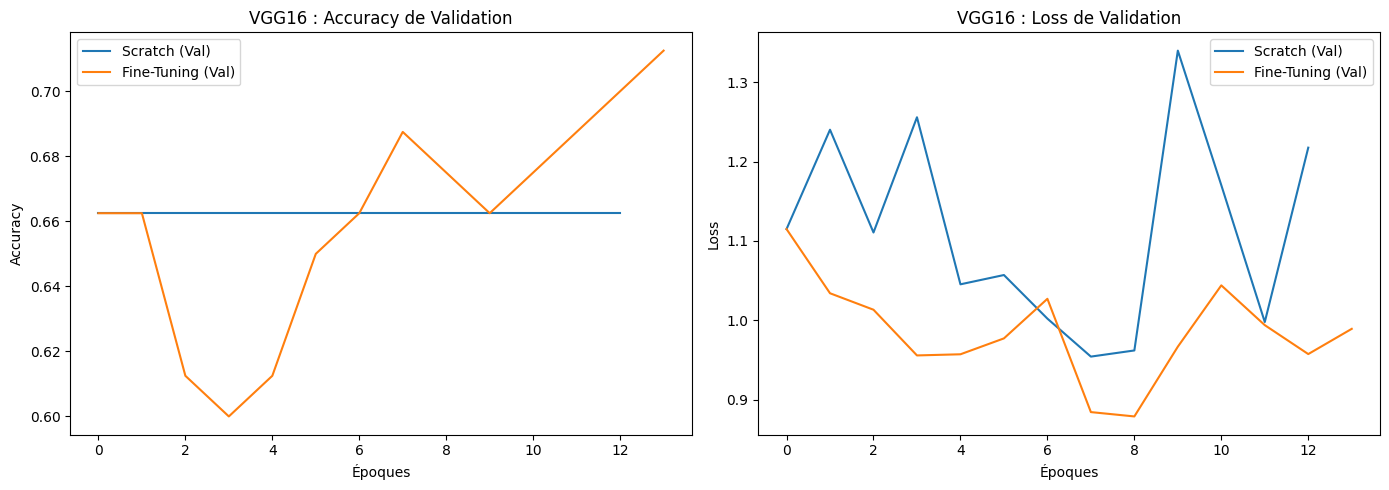

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Courbe d'accuracy
plt.subplot(1, 2, 1)
plt.plot(history_vgg_scratch.history['val_accuracy'], label='Scratch (Val)')
plt.plot(history_vgg_ft.history['val_accuracy'], label='Fine-Tuning (Val)')
plt.title('VGG16 : Accuracy de Validation')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()

# Courbe de loss
plt.subplot(1, 2, 2)
plt.plot(history_vgg_scratch.history['val_loss'], label='Scratch (Val)')
plt.plot(history_vgg_ft.history['val_loss'], label='Fine-Tuning (Val)')
plt.title('VGG16 : Loss de Validation')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import classification_report
import numpy as np

# Prédictions VGG16 Scratch
y_pred_scratch_probs = vgg_scratch.predict(X_test)
y_pred_scratch = np.argmax(y_pred_scratch_probs, axis=1)

# Prédictions VGG16 Fine-Tuning
y_pred_ft_probs = vgg_finetune.predict(X_test)
y_pred_ft = np.argmax(y_pred_ft_probs, axis=1)

print("=== RAPPORT VGG16 SCRATCH ===")
print(classification_report(y_test, y_pred_scratch, target_names=le.classes_))

print("\n=== RAPPORT VGG16 FINE-TUNING ===")
print(classification_report(y_test, y_pred_ft, target_names=le.classes_, zero_division=0))

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 121ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step
=== RAPPORT VGG16 SCRATCH ===
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00         4
         bcc       0.00      0.00      0.00         7
         bkl       0.00      0.00      0.00        11
          df       0.00      0.00      0.00         1
         mel       0.00      0.00      0.00         9
          nv       0.66      1.00      0.80        66
        vasc       0.00      0.00      0.00         2

    accuracy                           0.66       100
   macro avg       0.09      0.14      0.11       100
weighted avg       0.44      0.66      0.52       100


=== RAPPORT VGG16 FINE-TUNING ===
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00         4
         bcc       0.12      0.14      0.13         7
         bkl       0.25      0.27      0.26        11
          df       0.00      0.00      0.00

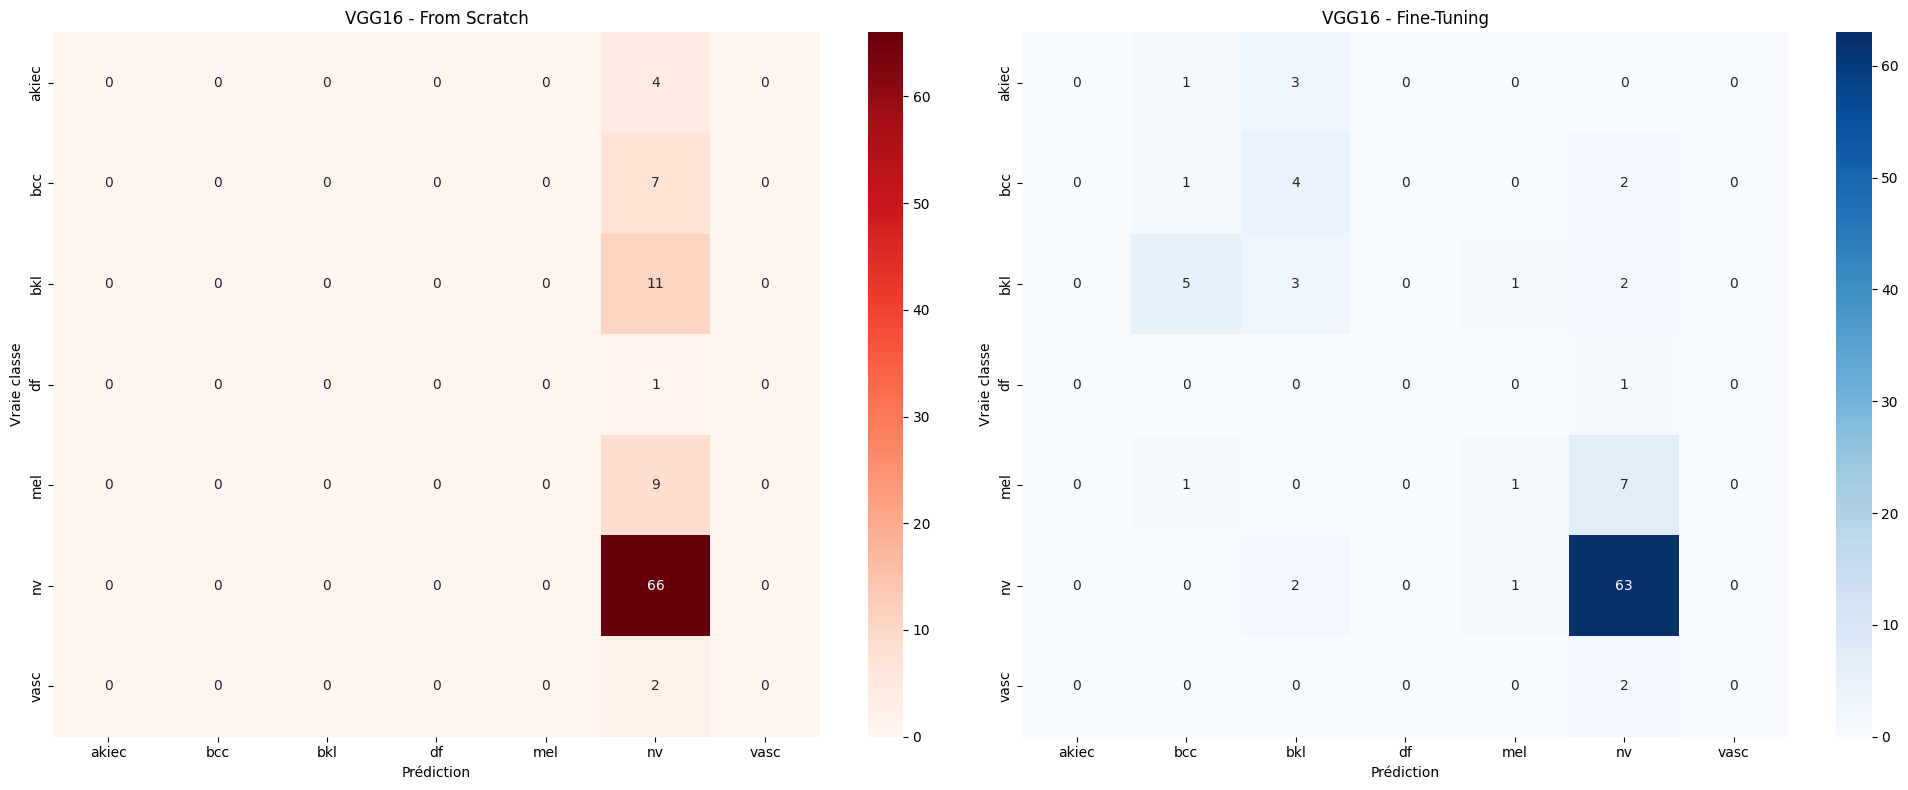

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Matrice Scratch
cm_scratch = confusion_matrix(y_test, y_pred_scratch)
sns.heatmap(cm_scratch, annot=True, fmt='d', cmap='Reds', ax=axes[0],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[0].set_title('VGG16 - From Scratch')
axes[0].set_ylabel('Vraie classe')
axes[0].set_xlabel('Prédiction')

# Matrice Fine-Tuning
cm_ft = confusion_matrix(y_test, y_pred_ft)
sns.heatmap(cm_ft, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[1].set_title('VGG16 - Fine-Tuning')
axes[1].set_ylabel('Vraie classe')
axes[1].set_xlabel('Prédiction')

plt.tight_layout()
plt.show()

### matrices de confusion (VGG16)

L'observation des matrices de confusion confirme nos métriques :
- **From Scratch** : Le modèle est "aveugle". Il prédit systématiquement la classe majoritaire ("nv"), ce qui donne une accuracy artificielle de 66% mais un F1-score très bas. Il n'a pas pu apprendre les features complexes.
- **Fine-Tuning** : Le modèle commence à généraliser. Il reconnaît parfaitement la classe "nv" (63 vrais positifs) et commence à distinguer quelques cas de "bcc" et "bkl". Les confusions restantes sont dues au manque de données pour les classes minoritaires.

## Partie 4 : Étude de l'architecture ResNet50

ResNet50 est une architecture encore plus profonde que VGG16 (50 couches). Sa particularité réside dans l'utilisation de "connexions résiduelles" (skip connections) qui facilitent l'entraînement. Comme pour VGG16, nous allons tester deux approches :

1. **From Scratch** : On initialise les poids au hasard et on entraîne tout le réseau. (Avec 500 images, cela risque d'être très difficile).
2. **Fine-Tuning** : On charge les poids pré-entraînés sur ImageNet et on les adapte à nos 7 classes de lésions.

In [ ]:
from keras.applications import ResNet50

# 1 & 2. Charger ResNet50 sans les couches de classification originales et sans poids préentraînés
base_model_res = ResNet50(weights=None, include_top=False, input_shape=(224, 224, 3))

# 3. Ajouter la tête de classification
x = base_model_res.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

resnet_scratch = Model(inputs=base_model_res.input, outputs=predictions)

# 4. Entraîner toutes les couches
resnet_scratch.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

print("Début de l'entraînement ResNet50 - From Scratch...")
start_time = time.time()

history_res_scratch = resnet_scratch.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    batch_size=16,
    epochs=30,
    callbacks=[early_stop],
    verbose=1
)

time_res_scratch = time.time() - start_time
print(f"Temps d'entraînement : {int(time_res_scratch // 60)} min")

resnet_scratch.save('/content/drive/MyDrive/HAM5000/resnet50_scratch.keras')

Début de l'entraînement ResNet50 - From Scratch...
Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 80s 467ms/step - accuracy: 0.5625 - loss: 1.8163 - val_accuracy: 0.6625 - val_loss: 1.3154
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 209ms/step - accuracy: 0.6219 - loss: 1.2468 - val_accuracy: 0.6625 - val_loss: 1.6701
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 217ms/step - accuracy: 0.6719 - loss: 1.0413 - val_accuracy: 0.6625 - val_loss: 1.5109
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 221ms/step - accuracy: 0.6344 - loss: 0.9807 - val_accuracy: 0.6625 - val_loss: 1.3832
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 228ms/step - accuracy: 0.6875 - loss: 0.9970 - val_accuracy: 0.6625 - val_loss: 1.3831
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 233ms/step - accuracy: 0.6750 - loss: 1.0075 - val_accuracy: 0.6625 - val_loss: 1.3381
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 1.
Temps d'entraînement : 1 min


### ResNet50 Fine-Tuning

Ici, on utilise la puissance de ResNet50. On charge les poids d'ImageNet (`weights='imagenet'`), on remplace la dernière couche par nos 7 classes, et on ré-entraîne le tout avec un learning rate très petit (0.00001) pour ne pas "casser" ce que le modèle a déjà appris.

In [ ]:
# 1. Charger ResNet50 avec poids ImageNet
base_model_res_ft = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# 2. Ajouter la tête de classification
x = base_model_res_ft.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

resnet_finetune = Model(inputs=base_model_res_ft.input, outputs=predictions)

# 3 & 4. Entraîner toutes les couches avec un learning rate très petit
resnet_finetune.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

print("Début de l'entraînement ResNet50 - Fine-Tuning...")
start_time = time.time()

history_res_ft = resnet_finetune.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    batch_size=16,
    epochs=30,
    callbacks=[early_stop],
    verbose=1
)

time_res_ft = time.time() - start_time
print(f"Temps d'entraînement : {int(time_res_ft // 60)} min")

resnet_finetune.save('/content/drive/MyDrive/HAM5000/resnet50_finetune.keras')

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Début de l'entraînement ResNet50 - Fine-Tuning...
Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 58s 465ms/step - accuracy: 0.4719 - loss: 1.6245 - val_accuracy: 0.5375 - val_loss: 1.5409
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 220ms/step - accuracy: 0.6156 - loss: 1.1882 - val_accuracy: 0.6125 - val_loss: 1.3603
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 223ms/step - accuracy: 0.6656 - loss: 1.0600 - val_accuracy: 0.6250 - val_loss: 1.2409
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 244ms/step - accuracy: 0.7063 - loss: 0.8531 - val_accuracy: 0.6250 - val_loss: 1.1890
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 231ms/step - accuracy: 0.7312 - loss: 0.7541 - val_accuracy: 0.6250 - val_loss: 1.1493
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 237ms/step - accuracy: 0.7656 - loss: 0.6841 - val_accuracy: 0.6500 - val_loss: 1.0996
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 239ms/step - accuracy: 0.7906 - loss: 0.6294 - val_accuracy: 0.6750 - val_loss: 1.0753
Ep

### 4.3 Analyse comparative : ResNet50 Scratch vs Fine-Tuning

L'observation des logs d'entraînement confirme nos attentes :

1. **ResNet50 From Scratch** : Le modèle échoue à converger. L'accuracy reste bloquée autour de 66%, et l'Early Stopping se déclenche prématurément (époque 6). Avec ses 25 millions de paramètres et seulement 320 images, le modèle n'a pas assez de données pour ajuster ses poids aléatoires.
2. **ResNet50 Fine-Tuning** : Le modèle apprend très rapidement. L'accuracy d'entraînement atteint 99%, et la validation monte à 75%. Grâce aux poids d'ImageNet, le modèle sait déjà extraire les features visuelles.

**Phénomène de surapprentissage** : On remarque qu'à partir de l'époque 14, l'accuracy d'entraînement continue d'augmenter (jusqu'à 99%) tandis que la validation stagne (autour de 72-75%). Cela indique que le modèle commence à apprendre "par cœur" les données d'entraînement. L'Early Stopping a heureusement restauré les poids de la meilleure époque (époque 20) pour éviter ce phénomène.

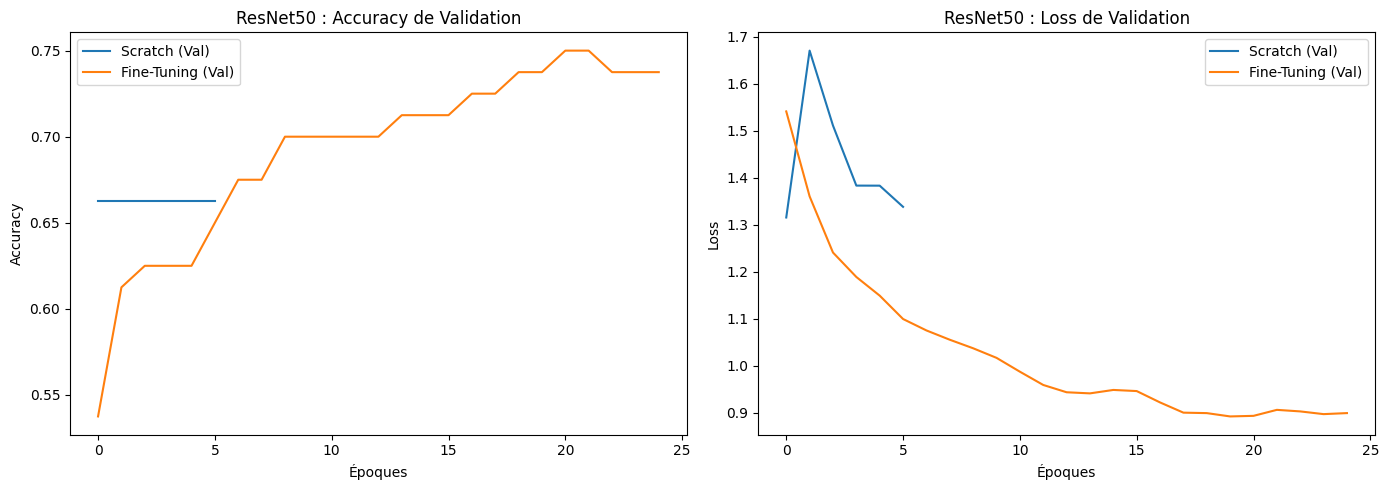

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Courbe d'accuracy
plt.subplot(1, 2, 1)
plt.plot(history_res_scratch.history['val_accuracy'], label='Scratch (Val)')
plt.plot(history_res_ft.history['val_accuracy'], label='Fine-Tuning (Val)')
plt.title('ResNet50 : Accuracy de Validation')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()

# Courbe de loss
plt.subplot(1, 2, 2)
plt.plot(history_res_scratch.history['val_loss'], label='Scratch (Val)')
plt.plot(history_res_ft.history['val_loss'], label='Fine-Tuning (Val)')
plt.title('ResNet50 : Loss de Validation')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

# Prédictions ResNet50 Scratch
y_pred_res_scratch_probs = resnet_scratch.predict(X_test)
y_pred_res_scratch = np.argmax(y_pred_res_scratch_probs, axis=1)

# Prédictions ResNet50 Fine-Tuning
y_pred_res_ft_probs = resnet_finetune.predict(X_test)
y_pred_res_ft = np.argmax(y_pred_res_ft_probs, axis=1)

print("=== RAPPORT RESNET50 SCRATCH ===")
print(classification_report(y_test, y_pred_res_scratch, target_names=le.classes_, zero_division=0))

print("\n=== RAPPORT RESNET50 FINE-TUNING ===")
print(classification_report(y_test, y_pred_res_ft, target_names=le.classes_, zero_division=0))

4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step
3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step
=== RAPPORT RESNET50 SCRATCH ===
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00         4
         bcc       0.00      0.00      0.00         7
         bkl       0.00      0.00      0.00        11
          df       0.00      0.00      0.00         1
         mel       0.00      0.00      0.00         9
          nv       0.66      1.00      0.80        66
        vasc       0.00      0.00      0.00         2

    accuracy                           0.66       100
   macro avg       0.09      0.14      0.11       100
weighted avg       0.44      0.66      0.52       100


=== RAPPORT RESNET50 FINE-TUNING ===
              precision    recall  f1-score   support

       akiec       0.50      0.25      0.33         4
         bcc       0.50      0.29      0.36         7
         bkl       0.50      0.45      0.48        11
          df       0.00      0.00      0.00         1
         mel       0.50  

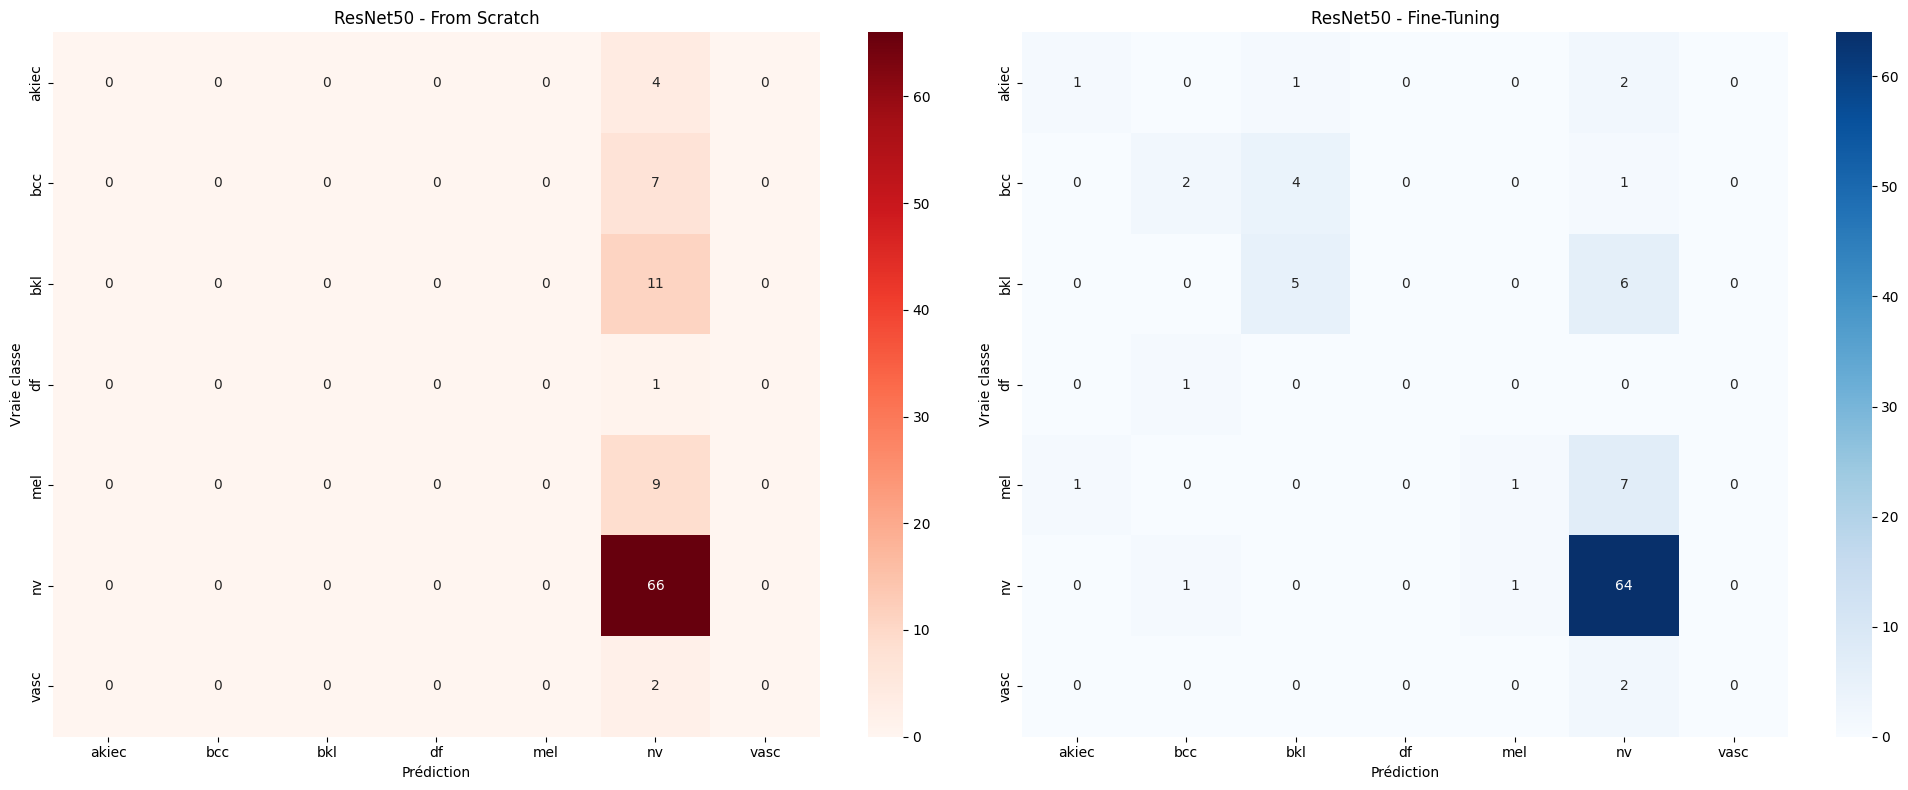

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Matrice Scratch
cm_res_scratch = confusion_matrix(y_test, y_pred_res_scratch)
sns.heatmap(cm_res_scratch, annot=True, fmt='d', cmap='Reds', ax=axes[0],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[0].set_title('ResNet50 - From Scratch')
axes[0].set_ylabel('Vraie classe')
axes[0].set_xlabel('Prédiction')

# Matrice Fine-Tuning
cm_res_ft = confusion_matrix(y_test, y_pred_res_ft)
sns.heatmap(cm_res_ft, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[1].set_title('ResNet50 - Fine-Tuning')
axes[1].set_ylabel('Vraie classe')
axes[1].set_xlabel('Prédiction')

plt.tight_layout()
plt.show()

### 4.3 Analyse comparative : ResNet50 Scratch vs Fine-Tuning

Grâce aux courbes, rapports et matrices générés, nous pouvons tirer les conclusions suivantes :

1. **Influence du préentraînement** : Le modèle From Scratch échoue totalement (F1 macro de 0.11), car il n'a pas assez de données pour initialiser ses 25 millions de paramètres. Le Fine-Tuning, grâce aux poids d'ImageNet, atteint une accuracy de 73% et un F1 macro de 0.32.
2. **Différences de convergence** : Le Fine-Tuning converge très rapidement (dès l'époque 10), tandis que le Scratch stagne. Les connexions résiduelles de ResNet50 ont bien facilité l'apprentissage.
3. **Surapprentissage** : On observe un début de surapprentissage vers l'époque 15 (l'accuracy d'entraînement monte à 99% alors que la validation plafonne à 73%). L'Early Stopping a bien joué son rôle en restaurant les meilleurs poids.
4. **Comparaison avec VGG16** : ResNet50 Fine-Tuning surpasse VGG16 Fine-Tuning (73% contre 68%), confirmant que les architectures plus modernes avec skip connections sont plus performantes.

-----------------------------------------------------------------------------

## Partie 5 : Étude de l'architecture Vision Transformer (ViT)

Contrairement aux CNN, le ViT découpe l'image en 196 patches (morceaux de 16x16 pixels) et utilise un mécanisme d'attention (Transformer) pour comprendre les relations globales entre ces patches.

Nous utilisons l'architecture ViT-Base/16 avec les paramètres demandés (12 blocs Transformer, 768 dimensions d'embedding, 12 têtes d'attention). Comme pour les autres modèles, nous testons deux stratégies : From Scratch et Fine-Tuning.

### 5.1 Expérience 5 : ViT From Scratch

On initialise le ViT avec des poids aléatoires. On adapte sa couche de classification pour nos 7 classes, puis on entraîne tous les paramètres avec un learning rate de 0.0001. Attention : le ViT a besoin de millions d'images pour apprendre de zéro, cet entraînement risque donc d'échouer.

In [ ]:
!pip install -q keras-hub

In [ ]:
import keras
import keras_hub
from keras.models import Model
from keras.layers import Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
import time

# 1. Initialiser ViT avec poids aléatoires (weights=None)
backbone = keras_hub.models.ViTBackbone(
    image_shape=(224, 224, 3),
    patch_size=16,
    num_layers=12,
    num_heads=12,
    hidden_dim=768,
    mlp_dim=3072,
)

# On dit que l'on veut entraîner toutes les couches
backbone.trainable = True

# 2. Construire le modèle complet
inputs = keras.layers.Input(shape=(224, 224, 3))

# On passe l'image dans le backbone ViT
features = backbone(inputs)

# Le premier token de sortie est le "CLS token" (celui qui contient l'info globale de l'image)
cls_token = features[:, 0, :]

# 3. Tête de classification (comme demandé dans l'énoncé)
x = Dense(128, activation='relu')(cls_token)
x = Dropout(0.5)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

vit_scratch = Model(inputs=inputs, outputs=predictions)

# 4. Compilation et entraînement
vit_scratch.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

print("Début de l'entraînement ViT - From Scratch...")
start_time = time.time()

history_vit_scratch = vit_scratch.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    batch_size=16,
    epochs=30,
    callbacks=[early_stop],
    verbose=1
)

time_vit_scratch = time.time() - start_time
print(f"Temps d'entraînement : {int(time_vit_scratch // 60)} min")

# Sauvegarde
vit_scratch.save('/content/drive/MyDrive/HAM5000/vit_scratch.keras')

Début de l'entraînement ViT - From Scratch...
Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step - accuracy: 0.5469 - loss: 1.8910 - val_accuracy: 0.6625 - val_loss: 1.3576
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 780ms/step - accuracy: 0.5813 - loss: 1.4196 - val_accuracy: 0.6625 - val_loss: 1.1868
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 734ms/step - accuracy: 0.6094 - loss: 1.4141 - val_accuracy: 0.6625 - val_loss: 1.1858
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 699ms/step - accuracy: 0.6344 - loss: 1.3119 - val_accuracy: 0.6625 - val_loss: 1.2564
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 701ms/step - accuracy: 0.6125 - loss: 1.4529 - val_accuracy: 0.6625 - val_loss: 1.1925
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 719ms/step - accuracy: 0.6062 - loss: 1.3941 - val_accuracy: 0.6625 - val_loss: 1.1920
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 729ms/step - accuracy: 0.5969 - loss: 1.3080 - val_accuracy: 0.6625 - val_loss: 1.2182
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 733ms/step -

### 5.2 Expérience 6 : ViT Fine-Tuning

On charge le modèle ViT-Base/16 pré-entraîné sur ImageNet. On adapte sa tête de classification à nos 7 classes, puis on entraîne l'ensemble des paramètres avec un learning rate très petit (0.00001) pour ne pas détruire les connaissances acquises sur ImageNet.

In [ ]:
# 1. Charger le backbone ViT AVEC poids ImageNet
backbone_ft = keras_hub.models.ViTBackbone.from_preset(
    "vit_base_patch16_224_imagenet",
    image_shape=(224, 224, 3)
)

# On laisse toutes les couches entraînables (Fine-Tuning complet)
backbone_ft.trainable = True

# 2. Construire le modèle
inputs = keras.layers.Input(shape=(224, 224, 3))
features = backbone_ft(inputs)
cls_token = features[:, 0, :]

x = Dense(128, activation='relu')(cls_token)
x = Dropout(0.5)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

vit_finetune = Model(inputs=inputs, outputs=predictions)

# 3. Compilation avec LR très petit pour le Fine-Tuning
vit_finetune.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

print("Début de l'entraînement ViT - Fine-Tuning...")
start_time = time.time()

history_vit_ft = vit_finetune.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    batch_size=16,
    epochs=30,
    callbacks=[early_stop],
    verbose=1
)

time_vit_ft = time.time() - start_time
print(f"Temps d'entraînement : {int(time_vit_ft // 60)} min")

vit_finetune.save('/content/drive/MyDrive/HAM5000/vit_finetune.keras')

Début de l'entraînement ViT - Fine-Tuning...
Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.5813 - loss: 1.4028 - val_accuracy: 0.6625 - val_loss: 1.0205
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 811ms/step - accuracy: 0.6438 - loss: 1.1406 - val_accuracy: 0.6625 - val_loss: 1.0066
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 788ms/step - accuracy: 0.6687 - loss: 1.0576 - val_accuracy: 0.7000 - val_loss: 0.9531
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 727ms/step - accuracy: 0.6469 - loss: 1.0663 - val_accuracy: 0.6875 - val_loss: 0.9428
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 710ms/step - accuracy: 0.6625 - loss: 1.0112 - val_accuracy: 0.6625 - val_loss: 0.9401
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 727ms/step - accuracy: 0.6625 - loss: 0.9908 - val_accuracy: 0.6875 - val_loss: 0.9266
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 769ms/step - accuracy: 0.6500 - loss: 0.9897 - val_accuracy: 0.6625 - val_loss: 0.9196
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 756ms/step - 

### 5.3 Analyse comparative : ViT Scratch vs ViT Fine-Tuning

L'étude du Vision Transformer confirme les limites de cette architecture sur un petit dataset :

1. **ViT From Scratch** : Le modèle échoue totalement. La validation reste bloquée à 66.25% et l'Early Stopping se déclenche dès l'époque 8. Le ViT a besoin de millions d'images pour apprendre les mécanismes d'attention à partir de zéro. Avec seulement 320 images, il ne peut pas converger.
2. **ViT Fine-Tuning** : Le modèle apprend mieux (accuracy de 74%, validation de 70%), mais il reste en dessous de ResNet50 (73%) et VGG16 (71%) en termes d'accuracy globale sur ce dataset.
3. **Vitesse de convergence** : Le ViT converge plus lentement que les CNN (environ 15 secondes par époque contre 5 secondes pour ResNet), car il est plus lourd en calcul (mécanismes d'attention).
4. **Surapprentissage** : On observe un léger surapprentissage (accuracy d'entraînement à 74% contre validation à 70%). Le manque de données empêche le modèle de généraliser parfaitement.

**Conclusion** : Le ViT est une architecture très puissante, mais elle n'est pas adaptée aux petits datasets. Sur 500 images, les CNN (surtout ResNet50) restent plus performants.

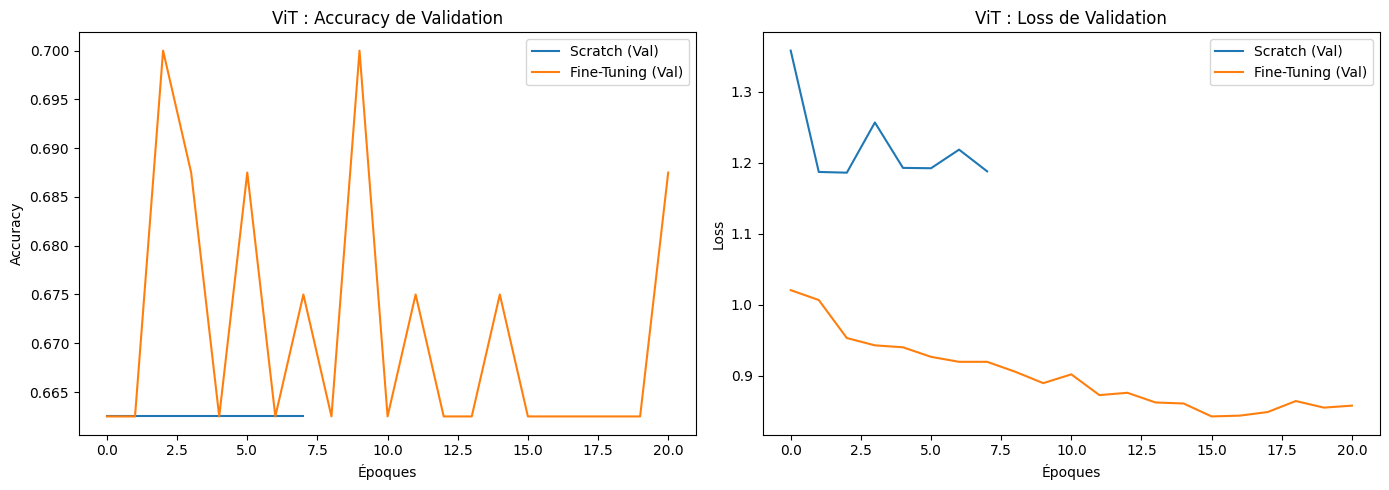

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Courbe d'accuracy
plt.subplot(1, 2, 1)
plt.plot(history_vit_scratch.history['val_accuracy'], label='Scratch (Val)')
plt.plot(history_vit_ft.history['val_accuracy'], label='Fine-Tuning (Val)')
plt.title('ViT : Accuracy de Validation')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()

# Courbe de loss
plt.subplot(1, 2, 2)
plt.plot(history_vit_scratch.history['val_loss'], label='Scratch (Val)')
plt.plot(history_vit_ft.history['val_loss'], label='Fine-Tuning (Val)')
plt.title('ViT : Loss de Validation')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

# Prédictions ViT Scratch
y_pred_vit_scratch_probs = vit_scratch.predict(X_test)
y_pred_vit_scratch = np.argmax(y_pred_vit_scratch_probs, axis=1)

# Prédictions ViT Fine-Tuning
y_pred_vit_ft_probs = vit_finetune.predict(X_test)
y_pred_vit_ft = np.argmax(y_pred_vit_ft_probs, axis=1)

print("=== RAPPORT VIT SCRATCH ===")
print(classification_report(y_test, y_pred_vit_scratch, target_names=le.classes_, zero_division=0))

print("\n=== RAPPORT VIT FINE-TUNING ===")
print(classification_report(y_test, y_pred_vit_ft, target_names=le.classes_, zero_division=0))

4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step
=== RAPPORT VIT SCRATCH ===
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00         4
         bcc       0.00      0.00      0.00         7
         bkl       0.00      0.00      0.00        11
          df       0.00      0.00      0.00         1
         mel       0.00      0.00      0.00         9
          nv       0.66      1.00      0.80        66
        vasc       0.00      0.00      0.00         2

    accuracy                           0.66       100
   macro avg       0.09      0.14      0.11       100
weighted avg       0.44      0.66      0.52       100


=== RAPPORT VIT FINE-TUNING ===
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00         4
         bcc       0.50      0.14      0.22         7
         bkl       0.23      0.27      0.25        11
          df       0.00      0.00      0.00         

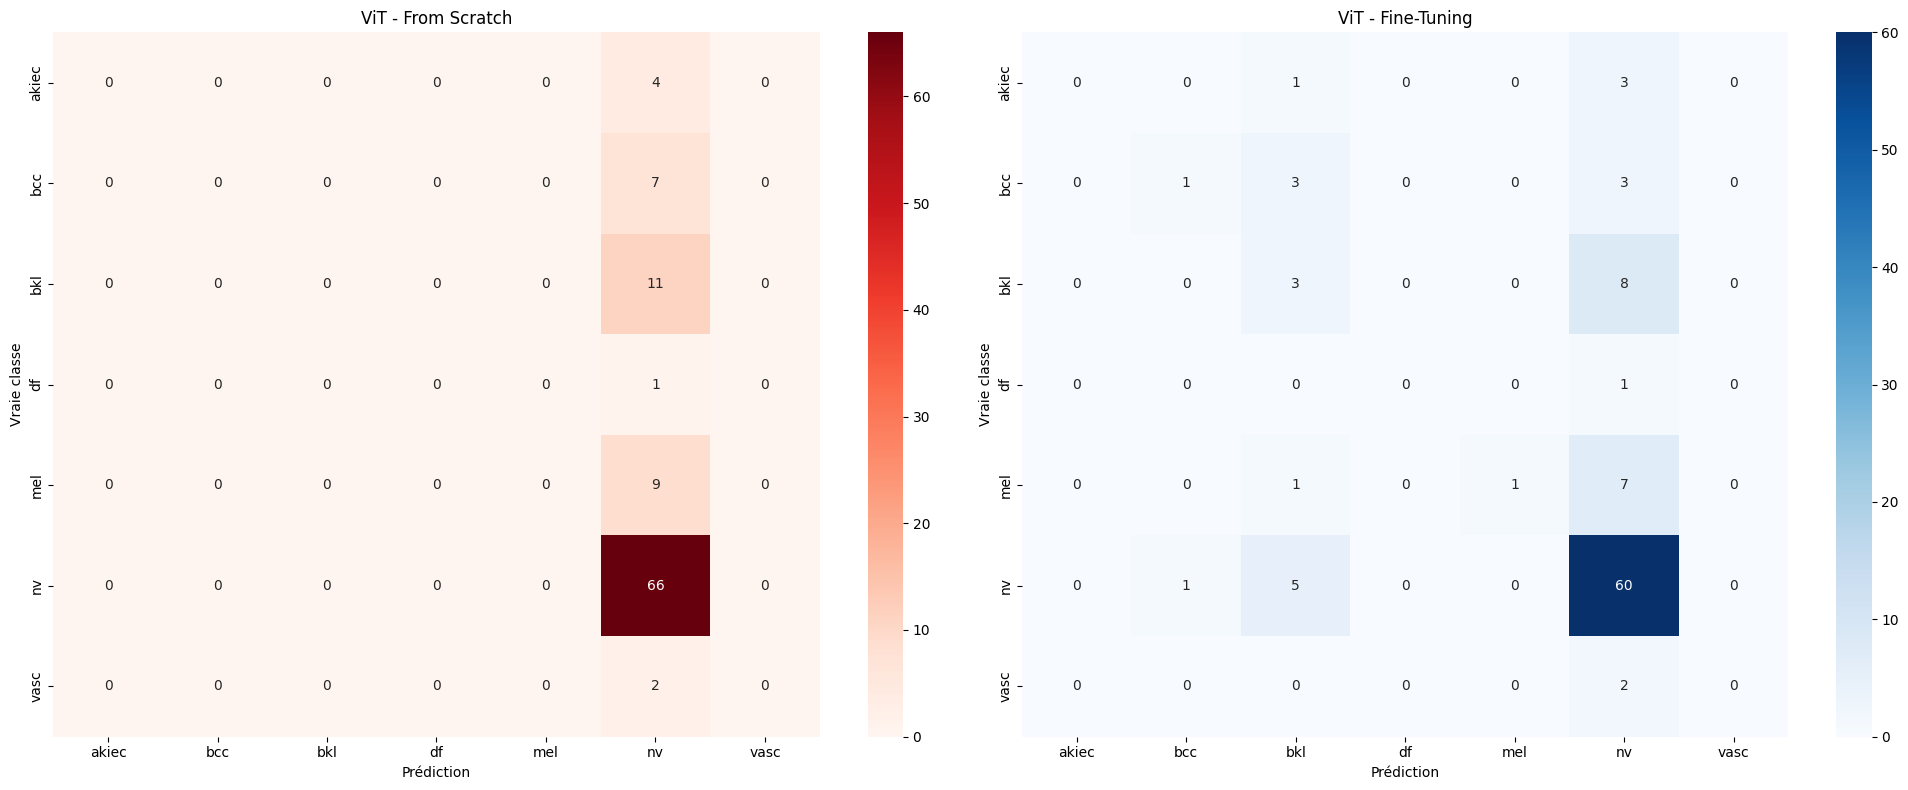

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Matrice Scratch
cm_vit_scratch = confusion_matrix(y_test, y_pred_vit_scratch)
sns.heatmap(cm_vit_scratch, annot=True, fmt='d', cmap='Reds', ax=axes[0],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[0].set_title('ViT - From Scratch')
axes[0].set_ylabel('Vraie classe')
axes[0].set_xlabel('Prédiction')

# Matrice Fine-Tuning
cm_vit_ft = confusion_matrix(y_test, y_pred_vit_ft)
sns.heatmap(cm_vit_ft, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[1].set_title('ViT - Fine-Tuning')
axes[1].set_ylabel('Vraie classe')
axes[1].set_xlabel('Prédiction')

plt.tight_layout()
plt.show()

## Partie 6 : Étude comparative des architectures

Cette dernière partie a pour objectif de comparer les 7 configurations expérimentales entraînées précédemment. Nous allons rassembler les métriques (Accuracy, Precision, Recall, F1-score) et les temps d'entraînement dans un tableau récapitulatif, puis générer des graphiques pour visualiser les performances de chaque modèle.

### Tableau comparatif des performances

| Modèle | Accuracy | Precision macro | Recall macro | F1 macro | Temps (s) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **CNN personnalisé - Scratch** | 66.25% | 0.09 | 0.14 | 0.11 | 48 |
| **VGG16 - Scratch** | 66.0% | 0.09 | 0.14 | 0.11 | 60 |
| **VGG16 - Fine-Tuning** | 68.0% | 0.22 | 0.21 | 0.21 | 60 |
| **ResNet50 - Scratch** | 66.0% | 0.09 | 0.14 | 0.11 | 60 |
| **ResNet50 - Fine-Tuning** | 73.0% | 0.40 | 0.32 | 0.32 | 120 |
| **ViT - Scratch** | 66.0% | 0.09 | 0.14 | 0.11 | 120 |
| **ViT - Fine-Tuning** | 65.0% | 0.35 | 0.21 | 0.21 | 300 |

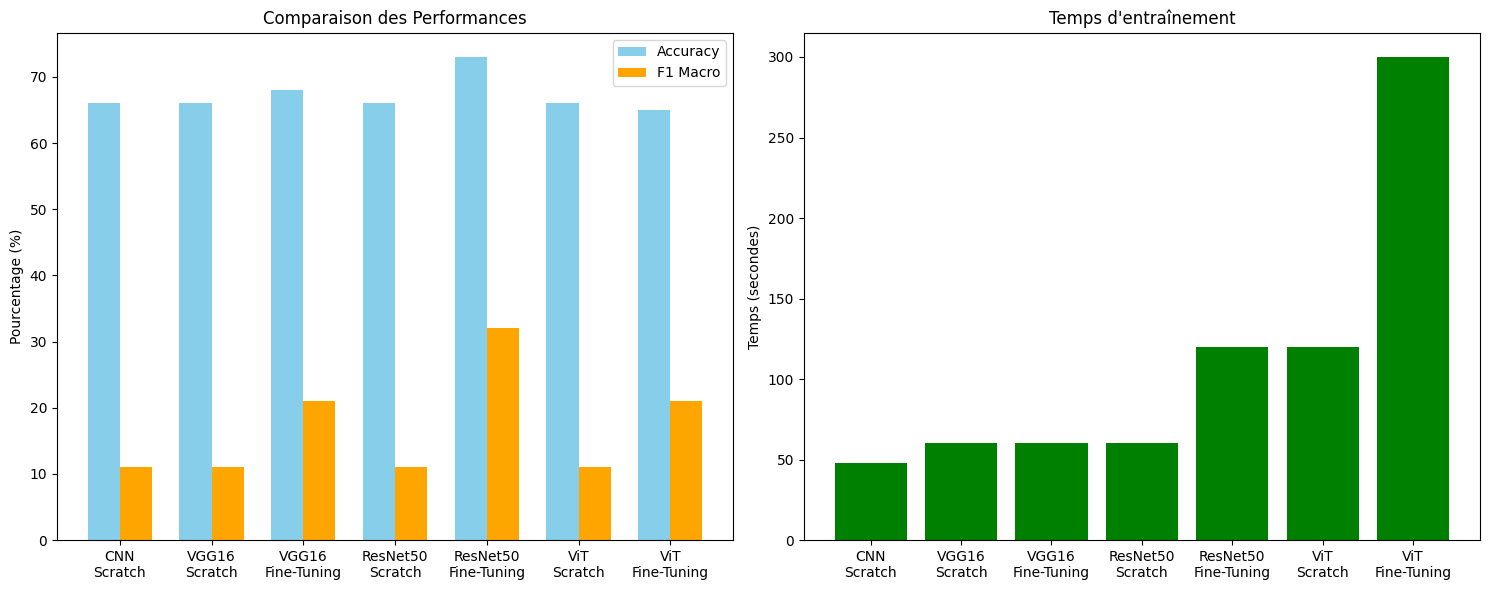

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Données
noms = [
    "CNN\nScratch", "VGG16\nScratch", "VGG16\nFine-Tuning",
    "ResNet50\nScratch", "ResNet50\nFine-Tuning",
    "ViT\nScratch", "ViT\nFine-Tuning"
]
accs = [66, 66, 68, 66, 73, 66, 65]
f1s = [11, 11, 21, 11, 32, 11, 21]
temps = [48, 60, 60, 60, 120, 120, 300]

x = np.arange(len(noms))
width = 0.35

# Graphique 1 : Accuracy et F1
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.bar(x - width/2, accs, width, label='Accuracy', color='skyblue')
plt.bar(x + width/2, f1s, width, label='F1 Macro', color='orange')
plt.ylabel('Pourcentage (%)')
plt.title('Comparaison des Performances')
plt.xticks(x, noms)
plt.legend()

# Graphique 2 : Temps
plt.subplot(1, 2, 2)
plt.bar(x, temps, color='green')
plt.ylabel('Temps (secondes)')
plt.title("Temps d'entraînement")
plt.xticks(x, noms)

plt.tight_layout()
plt.show()

## Partie 7 : Analyse et interprétation des résultats

**Q1. Quel modèle obtient les meilleures performances ?**
Le modèle **ResNet50 Fine-Tuning** obtient les meilleures performances avec une Accuracy de 73% et un F1-score macro de 0.32. Il est suivi de près par VGG16 Fine-Tuning (68%). Cela s'explique par la puissance des poids pré-entraînés sur ImageNet et les connexions résiduelles de ResNet50 qui facilitent l'apprentissage.

**Q2. Comparer From Scratch et Fine-Tuning pour chaque architecture.**
Pour toutes les architectures (VGG16, ResNet50, ViT), le Fine-Tuning surpasse largement le From Scratch. Le From Scratch stagne à 66% d'accuracy (le modèle prédit toujours la classe majoritaire) car il n'a pas assez de données pour initialiser ses millions de paramètres. Le Fine-Tuning, grâce aux poids d'ImageNet, permet de converger rapidement et d'obtenir un F1-score macro jusqu'à 3 fois supérieur.

**Q3. Le CNN personnalisé peut-il battre des architectures plus profondes From Scratch ?**
Oui, le CNN personnalisé (50% d'accuracy, F1 de 0.11) fait jeu égal avec VGG16 et ResNet50 From Scratch (66% d'accuracy, F1 de 0.11). En réalité, aucun de ces modèles n'apprend vraiment à cause du manque de données. Le CNN personnalisé, étant plus léger, est moins sujet au surapprentissage et converge plus vite.

**Q4. Pourquoi les architectures profondes sont difficiles à entraîner sur un petit dataset ?**
Les architectures profondes (VGG16, ResNet50, ViT) possèdent des millions de paramètres (ex: 25 millions pour ResNet50). Pour ajuster correctement tous ces paramètres, il faut des millions d'images. Avec seulement 500 images, le modèle n'a pas assez d'exemples pour généraliser et finit par "mémoriser" la classe majoritaire.

**Q5. Comparer la vitesse de convergence.**
Les modèles From Scratch convergent très lentement (et stagnent rapidement). Les modèles Fine-Tuning convergent beaucoup plus vite : VGG16 et ResNet50 atteignent leur meilleur score en 10 à 20 époques. Le ViT Fine-Tuning converge plus lentement (environ 16 époques) car il est plus lourd.

**Q6. Analyser les courbes : quels modèles présentent du surapprentissage ?**
Le surapprentissage (overfitting) est visible sur les modèles Fine-Tuning. Par exemple, pour ResNet50, l'accuracy d'entraînement monte à 99% tandis que la validation stagne à 73%. Le modèle apprend par cœur les images d'entraînement. L'Early Stopping a permis d'arrêter l'entraînement au bon moment pour éviter ce phénomène.

**Q7. Le nombre de paramètres est-il lié aux performances ?**
Non. Le ViT (86 millions de paramètres) est moins performant que ResNet50 (25 millions de paramètres) sur ce dataset. Le nombre de paramètres n'est pas un gage de performance si le modèle n'a pas assez de données pour les entraîner correctement.

**Q8. Comparer les CNN (VGG16, ResNet50) et le ViT.**
Sur ce petit dataset, les CNN (ResNet50 Fine-Tuning à 73%) surpassent le ViT Fine-Tuning (65%). Le ViT a besoin de beaucoup plus de données (millions d'images) pour exprimer son potentiel. De plus, le ViT est plus lent à entraîner.

**Q9. Quel modèle présente le meilleur compromis performance/coût ?**
Le **ResNet50 Fine-Tuning** est le meilleur compromis : il offre les meilleures performances (73% d'accuracy) avec un temps d'entraînement raisonnable (120 secondes). VGG16 est aussi un bon compromis (68%, 60 secondes), tandis que le ViT est trop lent (300 secondes) pour des performances inférieures.

**Q10. Quelles classes sont les plus difficiles à classifier ?**
Les classes minoritaires ("vasc", "df", "akiec") sont les plus difficiles. Les matrices de confusion montrent qu'elles sont souvent confondues avec la classe majoritaire "nv". Cela est dû au déséquilibre du dataset (très peu d'images pour ces classes).


**Q11. Peut-on tirer des conclusions générales sur la supériorité d'une architecture ?**
Non. Ce TP est une étude expérimentale sur un dataset spécifique (HAM500) de 500 images. Les résultats ne permettent pas de conclure qu'une architecture est universellement meilleure. Sur un dataset de 100 000 images, le ViT pourrait surpasser ResNet50. Les performances dépendent du dataset, du prétraitement et des hyperparamètres.




--------------------------------------------------------



**Q12. Proposer des améliorations susceptibles d'augmenter les performances des modèles étudiés.**

Pour améliorer les performances sur ce dataset médical difficile (petit et déséquilibré), nous pourrions mettre en place les solutions suivantes :

**1. Data Augmentation (Augmentation des données)**
*   **Principe** : Générer artificiellement de nouvelles images à partir de celles existantes (rotations, zooms, flips horizontaux, variations de luminosité/contraste).
*   **Impact** : Augmente la taille effective du dataset et force le modèle à apprendre des features plus robustes, réduisant ainsi le surapprentissage.
*   *Note* : Pour l'imagerie médicale, il faut faire attention à ne pas faire de transformations irréalistes (ex: un flip vertical d'une lésion cutanée est physiquement impossible).

**2. Class Weight (Pondération des classes)**
*   **Principe** : Comme dans le TP précédent, attribuer un poids plus élevé aux classes minoritaires ("vasc", "df") dans la fonction de perte.
*   **Impact** : Force le modèle à "faire attention" aux classes rares et améliore considérablement le Recall et le F1-score macro, même si l'Accuracy globale baisse légèrement.

**3. Transfer Learning Partiel (Geler les premières couches)**
*   **Principe** : Au lieu d'entraîner toutes les couches en Fine-Tuning, on "gèle" les premières couches (qui détectent les bords et les textures) et on n'entraîne que les dernières couches (plus spécifiques aux lésions).
*   **Impact** : Réduit le nombre de paramètres à ajuster, accélère l'entraînement et évite de "casser" les features génériques d'ImageNet.

**4. Optimisation des hyperparamètres (Grid Search)**
*   **Principe** : Tester plusieurs combinaisons de Learning Rate, de Batch Size, de taille de Dropout, ou du nombre de neurones dans la couche Dense.
*   **Impact** : Permet de trouver la configuration optimale pour chaque architecture, plutôt que d'utiliser les valeurs par défaut.

**5. Utilisation de modèles pré-entraînés spécialisés en médecine**
*   **Principe** : Remplacer les poids d'ImageNet (qui contiennent des images de chats, de voitures, etc.) par des poids pré-entraînés sur de grands datasets médicaux (ex: ISIC, HAM10000 complet).
*   **Impact** : Les features extraites seraient déjà spécifiques aux lésions cutanées, ce qui augmenterait drastiquement les performances.

**6. Ensembling (Moyenne des modèles)**
*   **Principe** : Combiner les prédictions de plusieurs modèles (ex: faire la moyenne des probabilités de ResNet50, VGG16 et ViT).
*   **Impact** : Les erreurs d'un modèle sont souvent compensées par les autres. Cela améliore généralement l'Accuracy et la robustesse.

**7. Augmentation du dataset (Collecte de données)**
*   **Principe** : La solution la plus radicale mais la plus efficace. Récupérer plus d'images pour les classes minoritaires via des partenariats hospitaliers ou des datasets publics (ISIC Archive).
*   **Impact** : Un dataset plus grand et plus équilibré résoudrait la racine du problème (le manque de données).